In [ ]:
# Librerias
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import folium
import branca
import numpy as np

# Exploracion del dataset de produccion no convencional

In [ ]:
#Permite ejecutar desde la raiz del proyecto o desde noteboooks/.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

ruta_csv = raiz / "data" / "raw" / "produccion-no-convencional.csv"

print("Archivo encontrado:", ruta_csv.is_file())

Archivo encontrado: False


In [ ]:
# df = pd.read_csv(
#     ruta_csv,
#     encoding="utf-8-sig",
#     low_memory=False
# )

# Carga del dataset online
df = pd.read_csv(
    "http://datos.energia.gob.ar/dataset/c846e79c-026c-4040-897f-1ad3543b407c/resource/b5b58cdc-9e07-41f9-b392-fb9ec68b0725/download/produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv",
    encoding="utf-8-sig",
    low_memory=False
)

print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]:,}")
display(df.head())

Filas: 426,145
Columnas: 40


,idempresa,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,iny_gas,iny_co2,...,cuenca,provincia,coordenadax,coordenaday,tipo_de_recurso,proyecto,clasificacion,subclasificacion,sub_tipo_recurso,fecha_data
0,YSUR,2017,1,155254,65.83,945.72,26.81,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.810599,-39.024277,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2017-01-31
1,YSUR,2015,1,131068,13.78,224.11,5.75,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.878573,-39.009753,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2015-01-31
2,YSUR,2017,1,154941,27.91,145.38,3.72,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.847093,-39.010145,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2017-01-31
3,YSUR,2015,1,136581,0.00,91.12,8.95,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-69.195470,-39.088767,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2015-01-31
4,YSUR,2017,1,136448,0.00,46.68,0.00,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-69.202449,-39.081680,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2017-01-31


|  # | Campo                    | Tipo      | Descripción                                                |
| -: | ------------------------ | --------- | ---------------------------------------------------------- |
|  0 | `idempresa`              | `str`     | Identificador de la empresa operadora del pozo.            |
|  1 | `anio`                   | `int64`   | Año informado.                                             |
|  2 | `mes`                    | `int64`   | Mes informado.                                             |
|  3 | `idpozo`                 | `int64`   | Identificador del pozo por formación productiva.           |
|  4 | `prod_pet`               | `float64` | Producción de petróleo (en m³).                            |
|  5 | `prod_gas`               | `float64` | Producción de gas (en miles de m³).                        |
|  6 | `prod_agua`              | `float64` | Producción de agua (en m³).                                |
|  7 | `iny_agua`               | `float64` | Inyección de agua (en m³).                                 |
|  8 | `iny_gas`                | `float64` | Inyección de gas (en miles de m³).                         |
|  9 | `iny_co2`                | `float64` | Inyección de CO₂ (en miles de m³).                         |
| 10 | `iny_otro`               | `float64` | Inyección de otros productos (en m³).                      |
| 11 | `tef`                    | `float64` | Tiempo efectivo de funcionamiento del pozo.                |
| 12 | `vida_util`              | `float64` | Vida útil estimada del pozo.                               |
| 13 | `tipoextraccion`         | `str`     | Tipo de extracción de los fluidos del pozo.                |
| 14 | `tipoestado`             | `str`     | Estado en el que se encuentra el pozo.                     |
| 15 | `tipopozo`               | `str`     | Característica de funcionamiento del pozo.                 |
| 16 | `observaciones`          | `str`     | Observaciones.                                             |
| 17 | `fechaingreso`           | `date-time`     | Fecha de carga de los datos.                               |
| 18 | `rectificado`            | `str`     | Indica si los datos fueron rectificados por el operador.   |
| 19 | `habilitado`             | `str`     | Indica si el registro está habilitado para su publicación. |
| 20 | `idusuario`              | `int64`   | Identificador del usuario de carga de los datos.           |
| 21 | `empresa`                | `str`     | Nombre de la empresa operadora.                            |
| 22 | `sigla`                  | `str`     | Identificador único de la boca del pozo.                   |
| 23 | `formprod`               | `str`     | Identificador de la formación productiva.                  |
| 24 | `profundidad`            | `float64` | Profundidad del pozo.                                      |
| 25 | `formacion`              | `str`     | Formación productiva.                                      |
| 26 | `idareapermisoconcesion` | `str`     | Identificador del área, permiso o concesión.               |
| 27 | `areapermisoconcesion`   | `str`     | Nombre del área, permiso o concesión.                      |
| 28 | `idareayacimiento`       | `str`     | Identificador del yacimiento.                              |
| 29 | `areayacimiento`         | `str`     | Nombre del yacimiento.                                     |
| 30 | `cuenca`                 | `str`     | Nombre de la cuenca sedimentaria.                          |
| 31 | `provincia`              | `str`     | Nombre de la provincia.                                    |
| 32 | `coordenadax`            | `float64` | Coordenada X del pozo.                                     |
| 33 | `coordenaday`            | `float64` | Coordenada Y del pozo.                                     |
| 34 | `tipo_de_recurso`        | `str`     | Tipo de recurso.                                           |
| 35 | `proyecto`               | `str`     | Nombre del proyecto asociado al pozo.                      |
| 36 | `clasificacion`          | `str`     | Clasificación del pozo.                                    |
| 37 | `subclasificacion`       | `str`     | Subclasificación del pozo.                                 |
| 38 | `sub_tipo_recurso`       | `str`     | Tipo de recurso hidrocarburífero.                          |
| 39 | `fecha_data`             | `date-time`     | Fecha asociada a los datos.                                |


**Campos que podemos descartar:**

| Campo | Razón |
|---|---|
| `fechaingreso` | Nos interesa la fecha de la data no la de ingreso de la data |

In [ ]:
# Descarte de la columna fechaingreso
df.drop(columns=['fechaingreso'], inplace=True)

Veremos la relación entre "idpozo", "formprod" y "sigla". Según los campos, idpozo y formprod identifican a un pozo mientras que "sigla" identifica a dicho pozo pero en forma de código único válido para Argentina

Comprobemos:<br>
Una pregunta natural sería ver si hay algún idpozo que está en diferentes formprod (formaciones)

In [ ]:
for col in ['idpozo', 'formprod', 'sigla']:
  print(f'Valores nulos del campo {col}:', df[col].isna().sum())

Valores nulos del campo idpozo: 0
Valores nulos del campo formprod: 0
Valores nulos del campo sigla: 0


In [ ]:
pozos_varias_formaciones = (
    df.groupby('idpozo')['formprod']
      .nunique()
      .loc[lambda x: x > 1]
)

print('Cantidad de idpozos en diferente formación:')
print(len(pozos_varias_formaciones))

Cantidad de idpozos en diferente formación:
0


In [ ]:
print('Número máximo de siglas correspondiente a un (idpozo, formprod):')
df.groupby(['idpozo', 'formprod'])['sigla'].nunique().max()

Número máximo de siglas correspondiente a un (idpozo, formprod):


1

Por lo que la relación (idpozo, formprod) corresponde a una única sigla, y viceversa

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426145 entries, 0 to 426144
Data columns (total 39 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   idempresa               426145 non-null  object 
 1   anio                    426145 non-null  int64  
 2   mes                     426145 non-null  int64  
 3   idpozo                  426145 non-null  int64  
 4   prod_pet                426145 non-null  float64
 5   prod_gas                426145 non-null  float64
 6   prod_agua               426145 non-null  float64
 7   iny_agua                426145 non-null  float64
 8   iny_gas                 426145 non-null  float64
 9   iny_co2                 426145 non-null  float64
 10  iny_otro                426145 non-null  float64
 11  tef                     426145 non-null  float64
 12  vida_util               9079 non-null    float64
 13  tipoextraccion          425527 non-null  object 
 14  tipoestado          

La columna "fecha_data" se deberá cambiar a tipo date-time. El resto de columnas están bien seteadas

In [ ]:
print("¿Todos los registros de fecha son YYYY-MM-DD o YYYY-DD-MM?")
print(df['fecha_data'].str.fullmatch(r'\d{4}-\d{2}-\d{2}').all())

print('¿Algún valor es YYYY-DD-MM?')
print(pd.to_datetime(df['fecha_data'], format='%Y-%d-%m', errors='coerce').notna().any())

¿Todos los registros de fecha son YYYY-MM-DD o YYYY-DD-MM?
True
¿Algún valor es YYYY-DD-MM?
False


Por lo que la columna fecha_data tiene formato YYYY-MM-DD

In [ ]:
# Seteo del tipo de dato para la columna fecha_data
df['fecha_data'] = pd.to_datetime(df['fecha_data'], format='%Y-%m-%d')

In [ ]:
print('¿La columna anio coincide con fecha_data?')
print((df['anio'] == df['fecha_data'].dt.year).all())

print('¿La columna mes coincide con fecha_data?')
print((df['mes'] == df['fecha_data'].dt.month).all())

¿La columna anio coincide con fecha_data?
True
¿La columna mes coincide con fecha_data?
True


In [ ]:
#Identificando el periodo disponible
print("Primer mes:", df['fecha_data'].min())
print("Ultimo mes:", df['fecha_data'].max())
print("Registros con fecha invalida:", df['fecha_data'].isna().sum())
print("Identificadores pozo-formacion:", df["idpozo"].nunique())

Primer mes: 2006-01-31 00:00:00
Ultimo mes: 2026-08-31 00:00:00
Registros con fecha invalida: 0
Identificadores pozo-formacion: 5126


Como los registros represetan los datos de todo el mes entonces nos quedaremos sólo con las columnas anio y mes y desecharemos la columna de fecha_data

In [ ]:
# Eliminación de la columna fecha_data
df.drop(columns=['fecha_data'], inplace=True)

In [ ]:
# Explorar que contiene el dataframe

for columna in ["empresa", "formacion", "tipopozo"]:
    print(f"\nRegistros por {columna}:")
    display(
        df[columna]
        .value_counts(dropna=False)
        .rename_axis(columna)
        .reset_index(name="registros")
    )


Registros por empresa:


,empresa,registros
0,YPF S.A.,231069
1,CAPEX S.A.,21413
2,PLUSPETROL S.A.,20874
3,PAN AMERICAN ENERGY SL,20409
4,COMPAÑÍA GENERAL DE COMBUSTIBLES S.A.,16108
5,TECPETROL S.A.,15857
6,TOTAL AUSTRAL S.A.,15849
7,PAMPA ENERGIA S.A.,13677
8,SHELL ARGENTINA S.A.,9250
9,VISTA ENERGY ARGENTINA SAU,8401



Registros por formacion:


,formacion,registros
0,vaca muerta,219848
1,lajas,77996
2,mulichinco,35008
3,los molles,28227
4,magallanes,15806
5,precuyo,14684
6,quintuco,11038
7,punta rosada,9691
8,agrio,5747
9,basamento,2188



Registros por tipopozo:


,tipopozo,registros
0,Gasífero,230259
1,Petrolífero,165815
2,Otro tipo,28610
3,Sumidero,735
4,NaN,618
5,Inyección de Agua,56
6,Inyección de Gas,51
7,Acuífero,1


## Inicio de selección de campos a utilizar para el análisis exploratorio y predictivo.

Nos quedamos con la empresa ypf que es la que más registros posee

In [ ]:
df_ypf = df[df['idempresa'] == 'YPF'].copy()
df_ypf.info()

<class 'pandas.core.frame.DataFrame'>
Index: 231069 entries, 7721 to 238789
Data columns (total 38 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   idempresa               231069 non-null  object 
 1   anio                    231069 non-null  int64  
 2   mes                     231069 non-null  int64  
 3   idpozo                  231069 non-null  int64  
 4   prod_pet                231069 non-null  float64
 5   prod_gas                231069 non-null  float64
 6   prod_agua               231069 non-null  float64
 7   iny_agua                231069 non-null  float64
 8   iny_gas                 231069 non-null  float64
 9   iny_co2                 231069 non-null  float64
 10  iny_otro                231069 non-null  float64
 11  tef                     231069 non-null  float64
 12  vida_util               383 non-null     float64
 13  tipoextraccion          231064 non-null  object 
 14  tipoestado            

Nuestra áreas propuestas de interes fueron seleccionadas por sus diferentes distribuciones de fluidos en la formación Vaca Muerta:
*   Loma Campana (mayormente petróleo volatil)
*   La Amarga Chica (petróleo negro)
*   El Orejano (gas seco)

In [ ]:
df_areas = df_ypf[df_ypf['areayacimiento'].isin(['LOMA CAMPANA', 'LA AMARGA CHICA', 'EL OREJANO'])].copy()
df_areas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47119 entries, 7721 to 238787
Data columns (total 38 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   idempresa               47119 non-null  object 
 1   anio                    47119 non-null  int64  
 2   mes                     47119 non-null  int64  
 3   idpozo                  47119 non-null  int64  
 4   prod_pet                47119 non-null  float64
 5   prod_gas                47119 non-null  float64
 6   prod_agua               47119 non-null  float64
 7   iny_agua                47119 non-null  float64
 8   iny_gas                 47119 non-null  float64
 9   iny_co2                 47119 non-null  float64
 10  iny_otro                47119 non-null  float64
 11  tef                     47119 non-null  float64
 12  vida_util               6 non-null      float64
 13  tipoextraccion          47119 non-null  object 
 14  tipoestado              47119 non-null 

En el dataset ypf de por sí reporta pocos datos en la columna vida_util y observaciones. El resto de datos no presentan valores nulos.

In [ ]:
categoricas = df_areas.select_dtypes(include=['object']).columns

for col in categoricas:
    print(f'\n{"=" * 60}')
    print(f'{col} ({df_areas[col].nunique()} valores únicos)')
    print('=' * 60)
    print(df_areas[col].value_counts(dropna=False))


idempresa (1 valores únicos)
idempresa
YPF    47119
Name: count, dtype: int64

tipoextraccion (8 valores únicos)
tipoextraccion
Surgencia Natural            27068
Bombeo Mecánico              17307
Plunger Lift                  1722
Sin Sistema de Extracción      838
Electrosumergible               83
Bombeo Hidráulico               72
Gas Lift                        16
Jet Pump                        13
Name: count, dtype: int64

tipoestado (13 valores únicos)
tipoestado
Extracción Efectiva                   35641
Parado Transitoriamente                4724
En Estudio                             2819
En Espera de Reparación                1468
A Abandonar                            1064
Abandonado                              543
En Inyección Efectiva                   315
Otras Situación Inactivo                215
En Reserva de Gas                       179
Abandono Temporario                      80
Parado Alta Relación Agua/Petróleo       61
En Reparación                         

La columna de observaciones no aporta información relevante.

Algunas columnas poseen sólo un valor único por el filtrado de área y empresa que se hizo por lo que no aportarán al análisis y posteriores modelos de machine learning.

Dichas columnas son idempresa, habilitado, empresa, cuenca, provincia, tipo_de_recurso, proyecto y sub_tipo_recurso.

En definitiva, el datasete "df_areas" posee información de la empresa ypf, sobre la cuenca neuquina, en la provincia de Neuquén, sin proyecto asociado y el tipo de recurso hidrocarburífero es el Shale (recurso no convencional)

Recurso no convencional: normalmente requiere técnicas como fractura hidráulica y, en muchos casos, perforación horizontal.

In [ ]:
# Las columnas formprod y formacion refieren a lo mismo, por las dudas se chequea:
df_areas[['formprod', 'formacion']].value_counts()

,,count
formprod,formacion,
VMUT,vaca muerta,46843
CENT,centenario,273
QTUC,quintuco,3


Efectivamente, es redundate tener ambas columnas.

In [ ]:
# Lo mismo pasa con idareapermisoconcesion, areapermisoconcesion y areayacimiento
df_areas[['idareayacimiento', 'idareapermisoconcesion', 'areapermisoconcesion', 'areayacimiento']].value_counts()

,,,,count
idareayacimiento,idareapermisoconcesion,areapermisoconcesion,areayacimiento,
LCAM,LCAM,LOMA CAMPANA,LOMA CAMPANA,21205
LAC,LAC,LA AMARGA CHICA,LA AMARGA CHICA,15359
ELOR,ELOR,EL OREJANO,EL OREJANO,10555


In [ ]:
numericas = df_areas.select_dtypes(include=['int64', 'float64']).columns

for col in numericas:
    print(f'\n{"=" * 60}')
    print(f'{col} ({df_areas[col].nunique()} valores únicos)')
    print('=' * 60)
    print(df_areas[col].value_counts(dropna=False))


anio (19 valores únicos)
anio
2025    6856
2024    6047
2023    5314
2026    4962
2022    4553
2021    3823
2020    3430
2019    3150
2018    2760
2017    2349
2016    1739
2015    1052
2014     740
2013     119
2006      60
2007      60
2012      46
2008      45
2011      14
Name: count, dtype: int64

mes (12 valores únicos)
mes
8     4214
7     4159
6     4119
5     4061
4     4009
3     3972
2     3900
1     3848
12    3783
11    3740
10    3676
9     3638
Name: count, dtype: int64

idpozo (634 valores únicos)
idpozo
135484    219
137008    208
145552    188
145551    188
145550    188
         ... 
167542      1
167543      1
167546      1
167547      1
167544      1
Name: count, Length: 634, dtype: int64

prod_pet (28162 valores únicos)
prod_pet
0.00      15786
1.06         10
7.56          9
12.54         8
11.20         8
          ...  
666.58        1
569.97        1
62.48         1
82.16         1
600.73        1
Name: count, Length: 28162, dtype: int64

prod_gas (22564 valo

Para las columnas numéricas el rango de años cubre 2006-2008 y 2011-2025, en esta última se nota un claro aumento de los datos año tras año.

Se cubren todos los meses, la inyección de agua sólo sucede en 314 datos, no hay inyección de gas, co2, ni de otro tipo.

Hay un usuario que cargó todos los datos de este dataframe.

La columna de vida_util detalla algunos datos con valor 0, habría que investigar a qué se deben

In [ ]:
# Se procede a eliminar columnas sin valor adicional
df_areas.drop(columns =['idusuario', 'observaciones', 'idempresa', 'habilitado',
                        'empresa', 'cuenca', 'provincia', 'tipo_de_recurso',
                        'proyecto', 'sub_tipo_recurso'], inplace=True)

# Se eliminan las columnas redundantes
df_areas.drop(columns=['formprod', 'idareayacimiento', 'idareapermisoconcesion', 'areapermisoconcesion', 'sigla'], inplace=True)

# Como no hay inyección de gas, co2 ni de otro tipo se eliminan dichas columnas
df_areas.drop(columns=['iny_gas', 'iny_co2', 'iny_otro'], inplace=True)

In [ ]:
# Investigación de los ceros en vida_util
df_areas[df_areas['vida_util']==0][['idpozo', 'formacion', 'tipoestado']]

,idpozo,formacion,tipoestado
62387,157858,vaca muerta,A Abandonar
71221,157858,vaca muerta,A Abandonar
89490,157858,vaca muerta,A Abandonar
106039,157858,vaca muerta,A Abandonar
125333,157858,vaca muerta,A Abandonar
163295,157858,vaca muerta,A Abandonar


Es sobre un mismo pozo que está en estado para abandondar así que el 0 es un valor válido

In [ ]:
df_areas[(df_areas['tipoestado'] == 'A Abandonar') & (df_areas['vida_util'] != 0)][['idpozo', 'formacion']].count()

,0
idpozo,1058
formacion,1058


Hay 1058 pozos con estado a abandonar pero que no se les setea vida_util = 0 por lo que dicha columna no aporta mucha información

## Inspección de pozos que inyectaron agua

Veamos los meses que se inyectó agua

In [ ]:
pozos_iny_agua = df_areas[df_areas['iny_agua'] > 0][['idpozo','formacion', 'prod_pet', 'prod_gas', 'prod_agua', 'tipoextraccion', 'tipoestado', 'tipopozo']]
pozos_iny_agua.head()

,idpozo,formacion,prod_pet,prod_gas,prod_agua,tipoextraccion,tipoestado,tipopozo
9644,163420,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero
9846,161956,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero
11237,164032,vaca muerta,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero
11681,164966,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero
12800,161956,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero


In [ ]:
pozos_iny_agua.value_counts()

,,,,,,,,count
idpozo,formacion,prod_pet,prod_gas,prod_agua,tipoextraccion,tipoestado,tipopozo,
161956,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero,70
163420,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero,50
164032,vaca muerta,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero,43
162479,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Inyección de Agua,37
164966,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero,32
165419,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero,27
162479,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero,24
166318,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero,14
166682,centenario,0.0,0.0,0.0,Sin Sistema de Extracción,En Inyección Efectiva,Sumidero,14


En esos meses sólo inyectaron agua, sin extraer nada, y los tipos de pozos son sumidero e inyección de agua.

**Pozo de Inyección de Agua:**<br>
Perforación profunda para introducir agua, salmuera o fluidos industriales en formaciones geológicas confinadas.

**Pozo Sumidero:**<br>
Excavación o pozo filtrante para recibir efluentes tratados (de pozos sépticos) o agua de lluvia y permitir su infiltración en el suelo.

## Datos duplicados y localización de los pozos

In [ ]:
print('Cantidad de filas duplicadas:', df_areas.duplicated().sum())

print('Cantidad de filas duplicadas considerando columna mes, anio e idpozo:', df_areas[['anio', 'mes', 'idpozo']].duplicated().sum())

Cantidad de filas duplicadas: 0
Cantidad de filas duplicadas considerando columna mes, anio e idpozo: 0


In [ ]:
df_pozos_ubicacion = (
    df_areas[['idpozo', 'areayacimiento', 'coordenadax', 'coordenaday']]
    .drop_duplicates()
)

# Colores únicos para cada área/yacimiento
areas = df_pozos_ubicacion['areayacimiento'].unique()

colormap = branca.colormap.linear.Set1_09.scale(0, len(areas) - 1)

colores = {
    area: colormap(i)
    for i, area in enumerate(areas)
}

m = folium.Map(
    location=[
        df_pozos_ubicacion['coordenaday'].mean(),
        df_pozos_ubicacion['coordenadax'].mean()
    ],
    zoom_start=10,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Esri'
)

for _, row in df_pozos_ubicacion.dropna(
    subset=['coordenadax', 'coordenaday']
).iterrows():

    color = colores.get(row['areayacimiento'], 'gray')

    folium.CircleMarker(
        location=[row['coordenaday'], row['coordenadax']],
        radius=3,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8,
        popup=f"Pozo: {row['idpozo']}<br>"
              f"Área/Yacimiento: {row['areayacimiento']}"
    ).add_to(m)

m

## Filtrado del dataset

Se decidió poder avanzar con ciertas categorias exploratorias de los 3 yacimientos previamente filtrados. Dichas serán seleccionadas por la cantidad de datos que tengamos

In [ ]:
df_areas[['formacion', 'areayacimiento', 'tipopozo','tipoextraccion']].value_counts()

formacion    areayacimiento   tipopozo           tipoextraccion           
vaca muerta  LOMA CAMPANA     Petrolífero        Bombeo Mecánico              12284
             LA AMARGA CHICA  Petrolífero        Surgencia Natural            10176
             LOMA CAMPANA     Petrolífero        Surgencia Natural             6200
             EL OREJANO       Gasífero           Surgencia Natural             5735
             LA AMARGA CHICA  Petrolífero        Bombeo Mecánico               4327
             EL OREJANO       Otro tipo          Surgencia Natural             4287
             LOMA CAMPANA     Petrolífero        Plunger Lift                  1278
                              Otro tipo          Bombeo Mecánico                590
                                                 Surgencia Natural              535
             EL OREJANO       Otro tipo          Sin Sistema de Extracción      320
             LA AMARGA CHICA  Petrolífero        Plunger Lift                   311
centenario   LA AMARGA CHICA  Sumidero           Sin Sistema de Extracción      231
vaca muerta  LOMA CAMPANA     Otro tipo          Sin Sistema de Extracción      201
             EL OREJANO       Gasífero           Plunger Lift                   132
             LA AMARGA CHICA  Otro tipo          Bombeo Mecánico                106
             LOMA CAMPANA     Petrolífero        Bombeo Hidráulico               72
             LA AMARGA CHICA  Otro tipo          Surgencia Natural               70
                              Petrolífero        Electrosumergible               62
             EL OREJANO       Petrolífero        Surgencia Natural               61
             LOMA CAMPANA     Sumidero           Sin Sistema de Extracción       43
centenario   LA AMARGA CHICA  Inyección de Agua  Sin Sistema de Extracción       42
vaca muerta  EL OREJANO       Otro tipo          Electrosumergible               20
             LA AMARGA CHICA  Petrolífero        Gas Lift                        16
                                                 Jet Pump                        13
quintuco     LA AMARGA CHICA  Petrolífero        Surgencia Natural                3
vaca muerta  LA AMARGA CHICA  Otro tipo          Plunger Lift                     1
                              Petrolífero        Sin Sistema de Extracción        1
             LOMA CAMPANA     Gasífero           Surgencia Natural                1
                              Petrolífero        Electrosumergible                1
Name: count, dtype: int64

Los pozos pasan por varios tipos de extracción a lo largo de su vida útil, veamos cuáles

In [ ]:
# Obtener el conjunto de tipos de extracción únicos por pozo
pozos_comb = (
    df_areas.groupby('idpozo')['tipoextraccion']
    .agg(lambda x: tuple(sorted(set(x.dropna()))))
)

# Contar la cantidad de pozos por cada combinación de tipos de extracción
conteo_combinaciones = pozos_comb.value_counts().reset_index()
conteo_combinaciones.columns = ['Combinacion_Tipos', 'Cantidad_Pozos']

# Mostrar el resultado ordenado por la cantidad de pozos de mayor a menor
display(conteo_combinaciones)

,Combinacion_Tipos,Cantidad_Pozos
0,"(Bombeo Mecánico, Surgencia Natural)",286
1,"(Surgencia Natural,)",224
2,"(Bombeo Mecánico, Plunger Lift, Surgencia Natu...",36
3,"(Bombeo Mecánico, Plunger Lift, Sin Sistema de...",20
4,"(Sin Sistema de Extracción, Surgencia Natural)",19
5,"(Plunger Lift, Sin Sistema de Extracción, Surg...",12
6,"(Sin Sistema de Extracción,)",11
7,"(Plunger Lift, Surgencia Natural)",7
8,"(Electrosumergible, Surgencia Natural)",6
9,"(Gas Lift, Surgencia Natural)",4


La mayoría de datos viene dado por vaca muerta, las tres areas que abarcamos, los tipos de pozos petrolíferos y gasíferos y el tipo de extracción bombeo mecánico y surgencia natural.

Considerando todo esto decidimos filtrar más el dataset.

In [ ]:
# Filtrado final
df_filtrado = df_areas[(df_areas['formacion'] == 'vaca muerta') & (df_areas['tipopozo'].isin(['Petrolífero', 'Gasífero'])) & (df_areas['tipoextraccion'].isin(['Bombeo Mecánico', 'Surgencia Natural']))].copy()
df_filtrado.drop(columns=['formacion'], inplace=True)

## Creación de columnas

Las extracciones de petróleo, gas y agua dependen del tef (tiempo efectivo de extracción) por lo cual para el análisis es interesante ver cuál es la producción de dichos recursos por día efectivo

Por lo que se considera columnas nuevas, haciendo por ejemplo prod_pet / tef

In [ ]:
# Para no dividir por cero se tiene que hacer esto
df_filtrado['prod_pet_dia'] = np.where(
    df_filtrado['tef'] != 0,
    df_filtrado['prod_pet'] / df_filtrado['tef'],
    df_filtrado['prod_pet']
)

df_filtrado['prod_gas_dia'] = np.where(
    df_filtrado['tef'] != 0,
    df_filtrado['prod_gas'] / df_filtrado['tef'],
    df_filtrado['prod_gas']
)

df_filtrado['prod_agua_dia'] = np.where(
    df_filtrado['tef'] != 0,
    df_filtrado['prod_agua'] / df_filtrado['tef'],
    df_filtrado['prod_agua']
)

In [ ]:
df_filtrado[df_filtrado['tipoestado'] != "Extracción Efectiva"][["prod_pet_dia", "prod_gas_dia", "prod_agua_dia"]].describe()

,prod_pet_dia,prod_gas_dia,prod_agua_dia
count,4829.0,4829.0,4829.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,0.0
max,0.0,0.0,0.0


Sin el tipo de estado "extracción efectiva" no hay valores para ninguna extracción

In [ ]:
df_filtrado.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
anio,38784.0,NaN,NaN,NaN,2021.758148,3.259989,2011.0,2019.0,2022.0,2025.0,2026.0
mes,38784.0,NaN,NaN,NaN,6.450186,3.40691,1.0,4.0,6.0,9.0,12.0
idpozo,38784.0,NaN,NaN,NaN,157311.008973,6460.800024,135484.0,155033.0,158038.0,162406.0,167547.0
prod_pet,38784.0,NaN,NaN,NaN,801.592593,1268.500003,0.0,5.86,308.25,997.1825,12288.66
prod_gas,38784.0,NaN,NaN,NaN,366.252248,1048.813244,0.0,16.51,74.475,217.6675,14613.09
prod_agua,38784.0,NaN,NaN,NaN,301.518404,702.443137,0.0,0.5,40.32,252.7,15232.49
iny_agua,38784.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
tef,38784.0,NaN,NaN,NaN,23.556691,10.911552,0.0,21.35,29.56,30.69,31.0
vida_util,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipoextraccion,38784,2,Surgencia Natural,22173,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Una variable interesante a tener en cuenta es la edad del pozo, vamos a estimarla:

In [ ]:
df_filtrado['fecha'] = pd.to_datetime({
    'year': df_filtrado['anio'],
    'month': df_filtrado['mes'],
    'day': 1
})

df_filtrado['fecha_inicio_estimada'] = (
    df_filtrado.loc[df_filtrado['tipoestado'] == "Extracción Efectiva"]
      .groupby('idpozo')['fecha']
      .transform('min')
)

# Se crea la edad pozo en meses, si no hubo actividad productiva se le pone edad de pozo 0
df_filtrado['edad_pozo_meses'] = np.where(
    df_filtrado['fecha_inicio_estimada'].notna(),
    (df_filtrado['fecha'].dt.year - df_filtrado['fecha_inicio_estimada'].dt.year) * 12
    + (df_filtrado['fecha'].dt.month - df_filtrado['fecha_inicio_estimada'].dt.month),
    0
)

df_filtrado.drop(columns=['fecha', 'fecha_inicio_estimada'], inplace=True)
df_filtrado[['idpozo', 'edad_pozo_meses']].head()

,idpozo,edad_pozo_meses
7721,157336,86.0
7722,161686,11.0
7735,158425,4.0
7737,137008,84.0
7741,156708,20.0


## Análsis con gráficos

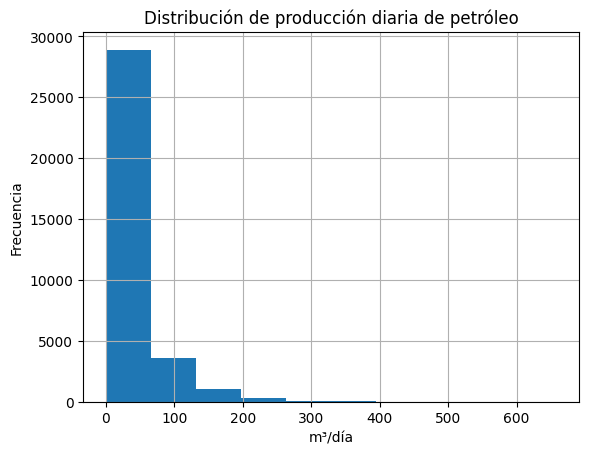

In [ ]:
df_filtrado[df_filtrado['tipoestado'] == 'Extracción Efectiva']['prod_pet_dia'].hist()
plt.title('Distribución de producción diaria de petróleo')
plt.xlabel('m³/día')
plt.ylabel('Frecuencia')
plt.show()

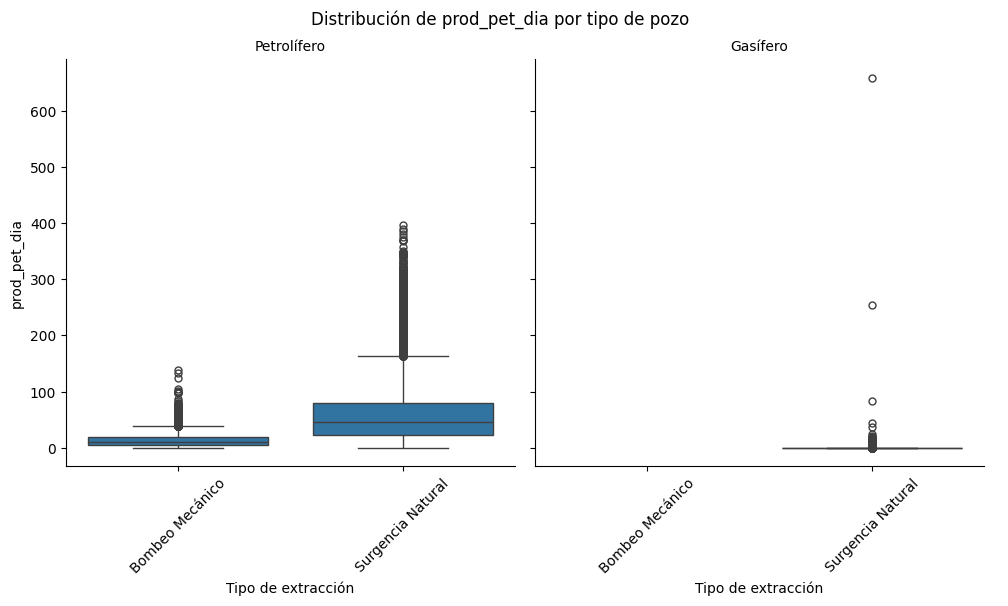

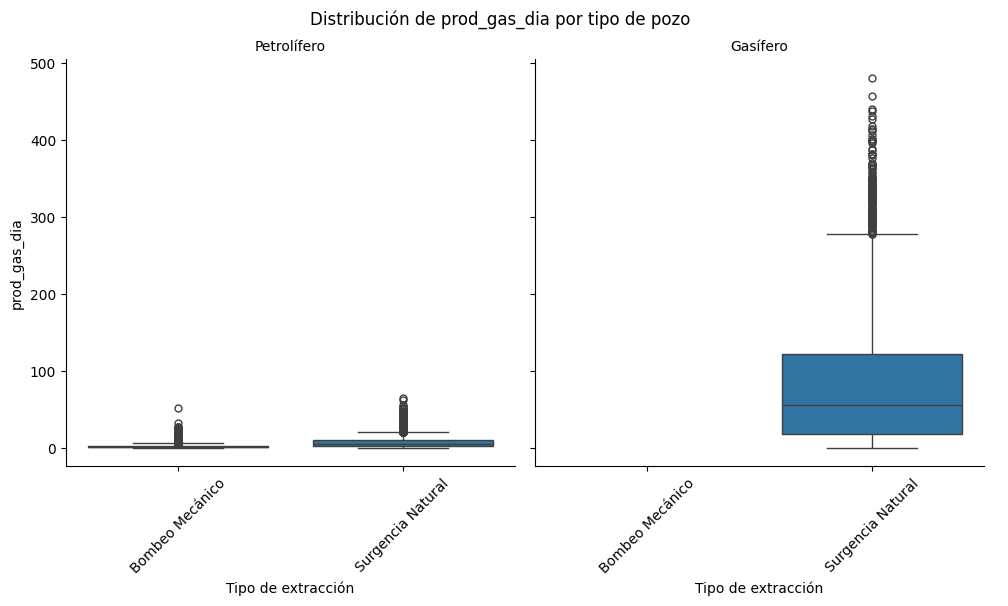

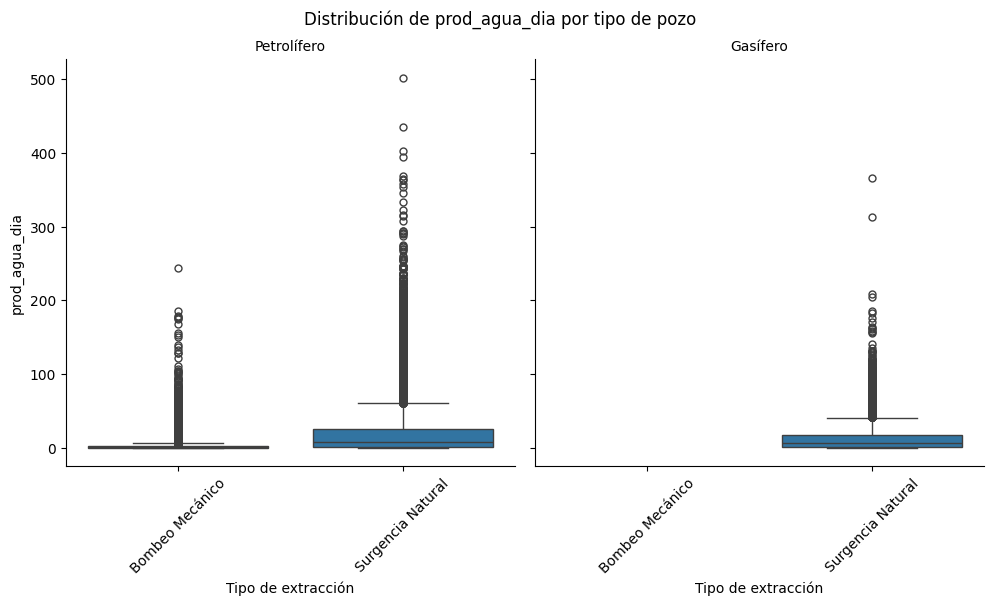

In [ ]:
df_plot = df_filtrado[df_filtrado['tipoestado'] == 'Extracción Efectiva'].copy()

cols = ['prod_pet_dia', 'prod_gas_dia', 'prod_agua_dia']

for col in cols:
    g = sns.catplot(
        data=df_plot,
        x='tipoextraccion',
        y=col,
        col='tipopozo',
        kind='box'
    )

    g.set_axis_labels('Tipo de extracción', col)
    g.set_titles('{col_name}')
    g.figure.suptitle(
        f'Distribución de {col} por tipo de pozo',
        y=1.03
    )

    for ax in g.axes.flat:
        ax.tick_params(axis='x', rotation=45)

    plt.show()

Como era esperable, los pozos petrolíferos y gasíferos se identifican por su extracción primaria del recurso al que hacen referencia.

La surgencia natural tiene una mejor extracción frente al bombeo mecánico.

In [ ]:
df_plot[df_plot['tipoextraccion'] == 'Surgencia Natural']['edad_pozo_meses'].describe()

,edad_pozo_meses
count,20235.000000
mean,28.971979
std,30.092864
min,0.000000
25%,8.000000
50%,19.000000
75%,38.000000
max,154.000000


La surgencia natural se usa principalmente en los primeros meses del pozo por lo que tiene sentido que la extracción sea mayor

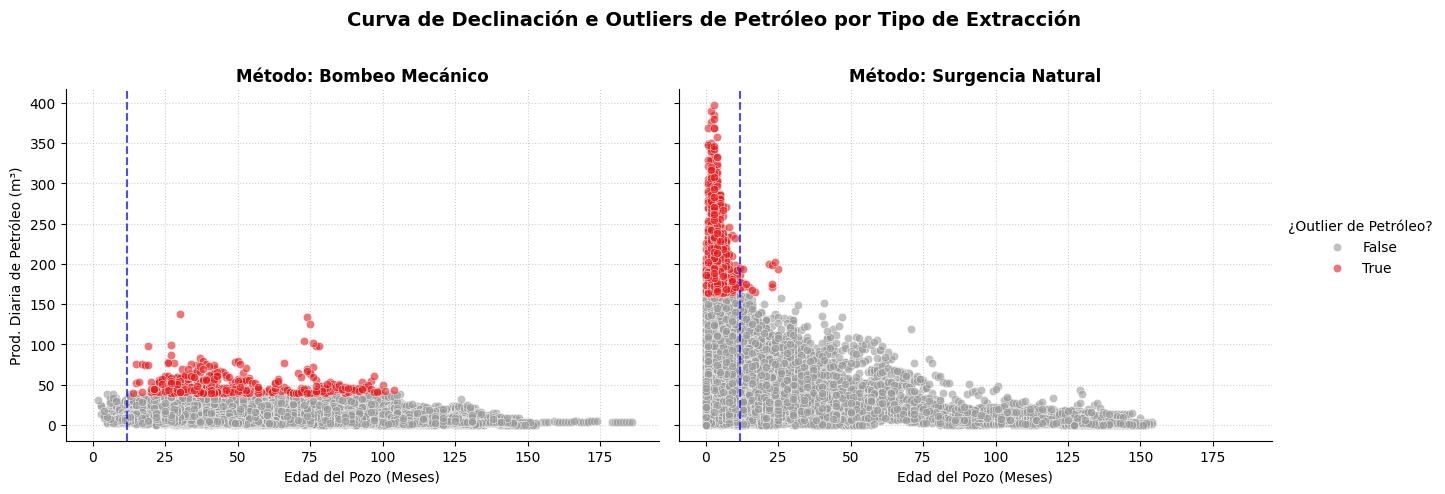

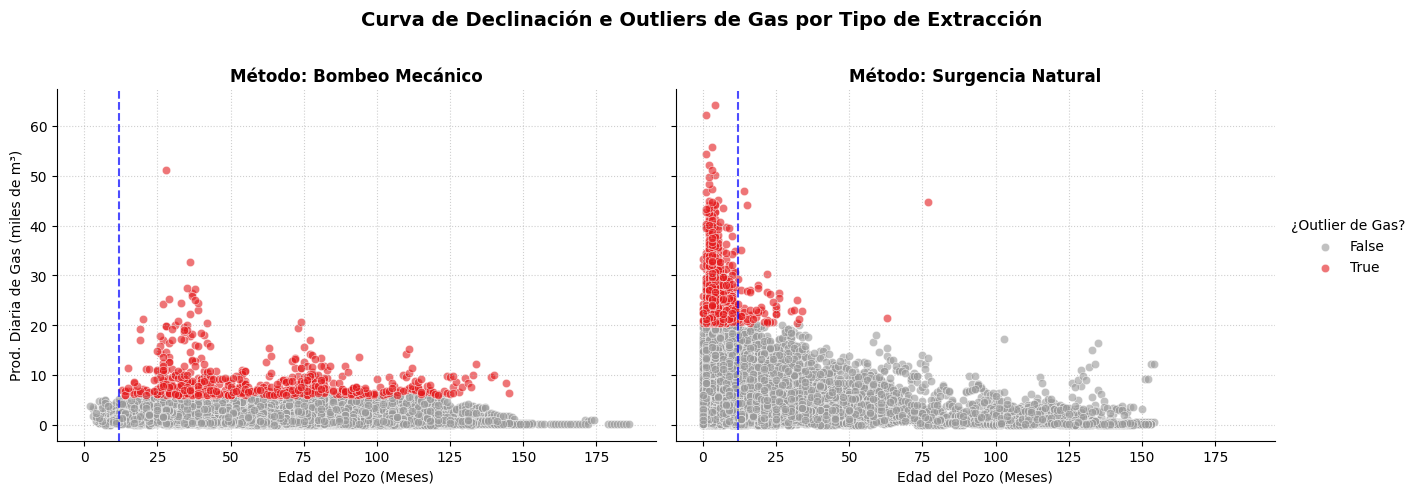

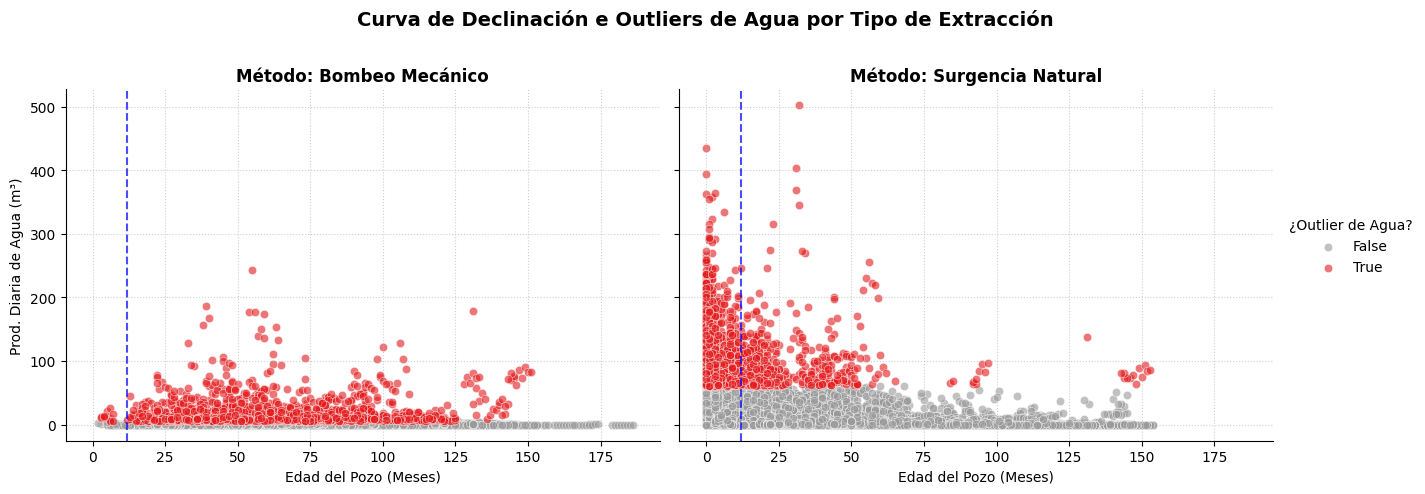

In [ ]:
df_plot = df_plot[df_plot['tipopozo'] == 'Petrolífero'].copy()

# 1. Identificar outliers por grupo usando el método IQR para cada fluido de manera independiente
fluidos = {
    'Petróleo': {'col_prod': 'prod_pet_dia', 'col_outlier': 'es_outlier_petroleo', 'unidad': 'm³'},
    'Gas': {'col_prod': 'prod_gas_dia', 'col_outlier': 'es_outlier_gas', 'unidad': 'miles de m³'},
    'Agua': {'col_prod': 'prod_agua_dia', 'col_outlier': 'es_outlier_agua', 'unidad': 'm³'}
}

for fluido, info in fluidos.items():
    col = info['col_prod']
    grupos = df_plot.groupby(['tipopozo', 'tipoextraccion'])[col]
    Q1 = grupos.transform('quantile', 0.25)
    Q3 = grupos.transform('quantile', 0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    df_plot[info['col_outlier']] = df_plot[col] > limite_superior

# 2. Visualizaciones individuales por cada tipo de fluido
for fluido, info in fluidos.items():
    g = sns.FacetGrid(
        data=df_plot,
        col='tipoextraccion',
        hue=info['col_outlier'],
        palette={True: '#e41a1c', False: '#999999'},
        height=5,
        aspect=1.3,
        hue_order=[False, True]
    )

    g.map_dataframe(
        sns.scatterplot,
        x='edad_pozo_meses',
        y=info['col_prod'],
        alpha=0.6
    )

    # Personalizar cada subgráfico
    for ax, title in zip(g.axes.flat, ['Bombeo Mecánico', 'Surgencia Natural']):
        ax.set_title(f'Método: {title}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Edad del Pozo (Meses)', fontsize=10)
        ax.set_ylabel(f'Prod. Diaria de {fluido} ({info["unidad"]})', fontsize=10)
        ax.axvline(x=12, color='blue', linestyle='--', alpha=0.7, label='Primer año')
        ax.grid(True, linestyle=':', alpha=0.6)

    g.add_legend(title=f'¿Outlier de {fluido}?')
    g.figure.subplots_adjust(top=0.82)
    g.figure.suptitle(f'Curva de Declinación e Outliers de {fluido} por Tipo de Extracción', fontsize=14, fontweight='bold')

    plt.show()

Para los pozos petrolífero, con el método de surgencia natural, los outliers suceden antes del año del pozo, indicando que se tienen una buena eficiencia en los primeros meses que luego decae y por ello se cambia de método de extracción

In [ ]:
produccion_anual = (
df_filtrado
.groupby('anio')[['prod_pet', 'prod_gas', 'prod_agua']]
.sum()
)
produccion_anual

,prod_pet,prod_gas,prod_agua
anio,,,
2011,5538.58,656.30,2764.34
2012,14830.28,3480.87,8579.45
2013,49575.50,14255.95,32369.34
2014,191566.30,98196.88,117264.77
2015,336163.57,298693.45,196420.19
2016,801419.98,567169.31,370010.97
2017,904466.51,1277892.13,492076.74
2018,1041924.58,1908432.08,496097.26
2019,1391723.88,1768294.86,437960.32


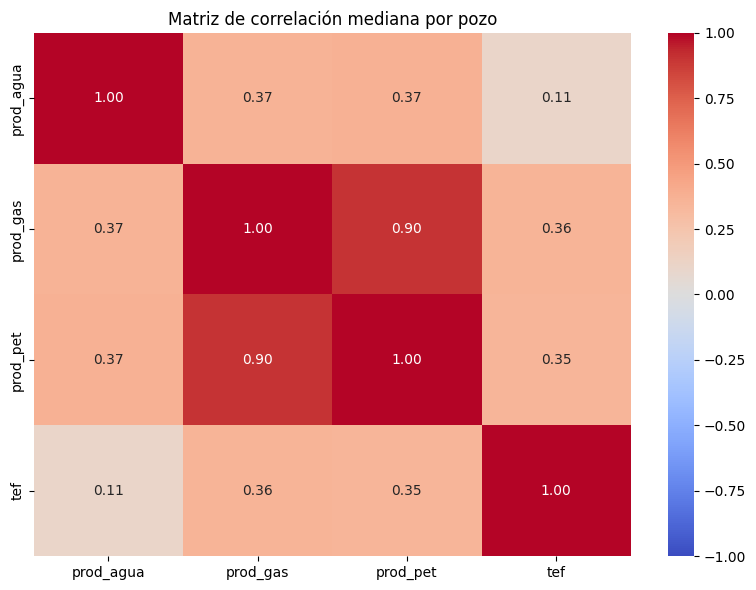

In [ ]:
cols = [
    'prod_agua',
    'prod_gas',
    'prod_pet',
    'tef'
]

corr_por_pozo = (
    df_areas[
        df_areas['tipoestado'] == 'Extracción Efectiva'
    ]
    .groupby('idpozo')[cols]
    .corr()
)

matriz_corr = (
    corr_por_pozo
    .groupby(level=1)
    .median()
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Matriz de correlación mediana por pozo')
plt.tight_layout()
plt.show()

La correlación es alta entre prod_pet y prod_gas